In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from ngo.numericalanalysis.linalg import torch_repeat

In [2]:
# class BSpline:
#     def __init__(self, n, p, C, dtype, device):
#         self.dtype = dtype
#         self.device = device
#         self.n = n
#         self.p = p  
#         self.C = C 
#         self.knot_vector = torch.zeros(self.p+1, dtype=self.dtype, device=self.device)
#         self.knot_vector = torch.cat((self.knot_vector, torch_repeat(torch.linspace(0, 1, int((self.n - self.p - 1)/(self.p - self.C)) + 2, dtype=self.dtype, device=self.device)[1:-1], self.p - self.C)))
#         self.knot_vector = torch.cat((self.knot_vector, torch.ones(self.p+1, dtype=self.dtype, device=self.device)))

#     def basis_function(self, i, p, x):
#         if p == 0:
#             return ((self.knot_vector[i] <= x) & (x <= self.knot_vector[i+1])).float()
#         else:
#             denom1 = self.knot_vector[i+p] - self.knot_vector[i]
#             denom2 = self.knot_vector[i+p+1] - self.knot_vector[i+1]
#             term1 = 0.0
#             term2 = 0.0
#             if denom1 > 0:
#                 term1 = (x - self.knot_vector[i]) / denom1 * self.basis_function(i, p-1, x)
#             if denom2 > 0:
#                 term2 = (self.knot_vector[i+p+1] - x) / denom2 * self.basis_function(i+1, p-1, x)
#             return term1 + term2
    
#     def evaluate(self, x):
#         N = torch.zeros((self.n, x.shape[0]), dtype=x.dtype, device=x.device)
#         for i in range(self.n):
#             N[i, :] = self.basis_function(i, self.p, x)
#         return N
    
#     def derivative(self, x):
#         dN = torch.zeros((self.n, x.shape[0]), dtype=x.dtype, device=x.device)
#         for i in range(self.n):
#             if self.p == 0:
#                 dN[i, :] = 0.0
#             else:
#                 denom1 = self.knot_vector[i+self.p] - self.knot_vector[i]
#                 denom2 = self.knot_vector[i+self.p+1] - self.knot_vector[i+1]
#                 term1 = 0.0
#                 term2 = 0.0
#                 if denom1 > 0:
#                     term1 = self.p / denom1 * self.basis_function(i, self.p-1, x)
#                 if denom2 > 0:
#                     term2 = -self.p / denom2 * self.basis_function(i+1, self.p-1, x)
#                 dN[i, :] = term1 + term2
#         return dN    
    

In [ ]:
# ...existing code...
class BSpline:
    """
    B-spline basis functions with vectorized evaluation and differentiation using PyTorch.
    """
    def __init__(self, n, p, C, dtype, device):
        """""
        Initialize the B-spline basis.

        Args:
            n: Number of basis functions.
            p: Degree of the B-splines.
            C: Continuity at internal knots (C < p).
            dtype: Torch data type for computations.
            device: Torch device for computations.
        """
        self.dtype = dtype
        self.device = device
        self.n = n
        self.p = p
        self.C = C
        self.knot_vector = torch.zeros(self.p+1, dtype=self.dtype, device=self.device)
        self.knot_vector = torch.cat((
            self.knot_vector,
            torch_repeat(
                torch.linspace(
                    0, 1,
                    int((self.n - self.p - 1)/(self.p - self.C)) + 2,
                    dtype=self.dtype, device=self.device
                )[1:-1],
                self.p - self.C
            )
        ))
        self.knot_vector = torch.cat((self.knot_vector, torch.ones(self.p+1, dtype=self.dtype, device=self.device)))

    def _basis_dp(self, x: torch.Tensor, return_prev: bool = False):
        """
        Vectorized Cox–de Boor evaluation for all basis functions in parallel.

        Args:
            x: 1D tensor of evaluation points, shape (M,).
            return_prev: If True, also returns N_{*,p-1}(x) for derivative.

        Returns:
            N_p: (n, M) values of N_{i,p}(x).
            N_pm1: (n, M) values of N_{i,p-1}(x) if return_prev=True, else None.
        """
        t = self.knot_vector
        x = x.to(dtype=self.dtype, device=self.device)
        n, p = self.n, self.p

        # Degree-0 indicator functions for all i in parallel
        t_i = t[:n].unsqueeze(1)       # (n,1)
        t_ip1 = t[1:n+1].unsqueeze(1)  # (n,1)
        N = ((t_i <= x) & (x <= t_ip1)).to(self.dtype)  # (n,M)

        if p == 0:
            return (N, None) if return_prev else N

        # Iteratively raise degree to p
        for r in range(1, p+1):
            den1 = (t[r:r+n] - t[:n]).unsqueeze(1)          # (n,1)
            den2 = (t[r+1:r+1+n] - t[1:n+1]).unsqueeze(1)   # (n,1)

            # Shift N for i+1 term
            N_ip1 = torch.cat([N[1:], torch.zeros_like(N[:1])], dim=0)

            # Weights with safe division
            w1 = torch.where(den1 > 0, (x - t[:n].unsqueeze(1)) / den1, torch.zeros_like(N))
            w2 = torch.where(den2 > 0, (t[r+1:r+1+n].unsqueeze(1) - x) / den2, torch.zeros_like(N))

            if return_prev and r == p:
                N_prev = N  # save N_{*,p-1}
            N = w1 * N + w2 * N_ip1

        return (N, N_prev) if return_prev else N

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Evaluate all B-spline basis functions N_{i,p}(x) in parallel.

        Args:
            x: 1D tensor of points, shape (M,).

        Returns:
            (n, M) tensor with N_{i,p}(x).
        """
        return self._basis_dp(x)

    def grad(self, x: torch.Tensor) -> torch.Tensor:
        """
        Evaluate derivatives d/dx N_{i,p}(x) for all i in parallel.

        Args:
            x: 1D tensor of points, shape (M,).

        Returns:
            (n, M) tensor with d/dx N_{i,p}(x).
        """
        N_p, N_pm1 = self._basis_dp(x, return_prev=True)
        n, p = self.n, self.p
        if p == 0:
            return torch.zeros_like(N_p)

        t = self.knot_vector
        den1 = (t[p:p+n] - t[:n]).unsqueeze(1)          # (n,1)
        den2 = (t[p+1:p+1+n] - t[1:n+1]).unsqueeze(1)   # (n,1)

        term1 = torch.where(den1 > 0, (p / den1) * N_pm1, torch.zeros_like(N_pm1))
        N_pm1_ip1 = torch.cat([N_pm1[1:], torch.zeros_like(N_pm1[:1])], dim=0)
        term2 = torch.where(den2 > 0, (p / den2) * N_pm1_ip1, torch.zeros_like(N_pm1))

        return term1 - term2

In [11]:
x = torch.linspace(0, 1, 1000, dtype=torch.float32, device='cuda')

In [12]:
basis = BSpline(n=10, p=3, C=2, dtype=torch.float32, device='cuda')

In [15]:
y = basis.forward(x)

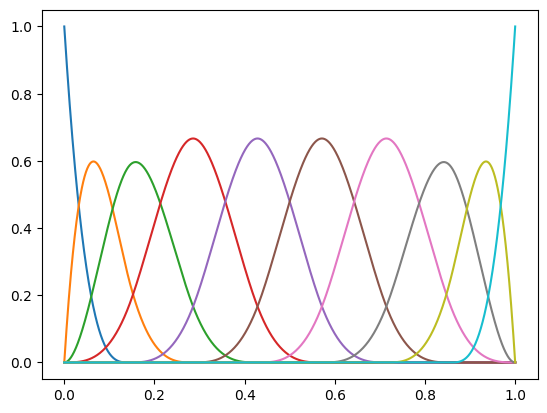

In [16]:
for i in range(basis.n):
    plt.plot(x.cpu(), y[i, :].cpu(), label=f'N_{i},{basis.p}')

In [19]:
y = basis.grad(x)

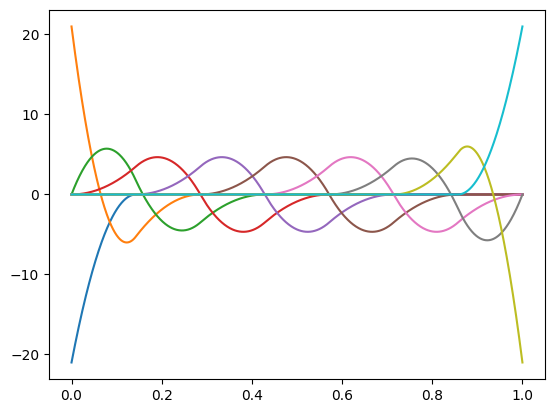

In [20]:
for i in range(basis.n):
    plt.plot(x.cpu(), y[i, :].cpu(), label=f'N_{i},{basis.p}')